# 04 · Evaluación y selección del modelo


**Criterio (ADR-03):** clasificación → **F1 de la clase positiva (`<30`)**, medido como F1 medio en validación cruzada; si hay empate (3 decimales), gana el de mayor **recall**. Regresión → menor **RMSE**.

In [1]:
import os
import sys

# Los notebooks viven en notebooks/; subimos a la raíz del proyecto para que funcionen las rutas
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import warnings

warnings.filterwarnings("ignore")

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src import evaluation as ev
from src.data import clean_data, load_data, split_train_test
from src.features import add_features
from src.models import SEED

ART = Path("artifacts")
%matplotlib inline

## 1. Datos de test y modelos guardados

In [2]:
df = clean_data(load_data())
X, y, y_reg, groups = add_features(df), df["target"], df["target_reg"], df["patient_nbr"]
tr, te = split_train_test(y, groups, seed=SEED)
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
yr_test = y_reg.iloc[te]

clf_names = ["GaussianNB", "DecisionTree", "RandomForest", "SVM"]
reg_names = ["DecisionTreeRegressor", "RandomForestRegressor", "SVR"]
models = {n: joblib.load(ART / "models" / f"{n}.joblib") for n in clf_names}
regressors = {n: joblib.load(ART / "models" / f"{n}.joblib") for n in reg_names}
print(f"test: {len(X_test):,} encuentros ({y_test.mean():.1%} positivos)")

test: 19,870 encuentros (11.4% positivos)


## 2. Tablas resumen (HU-11)

### Clasificación
Accuracy, precision y F1 son las métricas pedidas; recall es apoyo.

In [3]:
metrics = ev.compute_metrics(models, X_test, y_test)
metrics.set_index("model").sort_values("f1", ascending=False)

,accuracy,precision,recall,f1
model,,,,
RandomForest,0.6844,0.1802,0.4989,0.2647
SVM,0.6544,0.1740,0.5431,0.2636
DecisionTree,0.6540,0.1666,0.5095,0.2511
GaussianNB,0.8378,0.2336,0.1860,0.2071


### Regresión
MSE, MAE y RMSE sobre el target ordinal.

In [4]:
reg_metrics = ev.compute_regression_metrics(regressors, X_test, yr_test)
reg_metrics.set_index("model").sort_values("rmse")

,mse,mae,rmse
model,,,
RandomForestRegressor,0.4327,0.5625,0.6578
DecisionTreeRegressor,0.4396,0.5729,0.6631
SVR,0.4896,0.5212,0.6997


## 3. Gráficas comparativas (HU-12)

### Barras agrupadas de clasificación

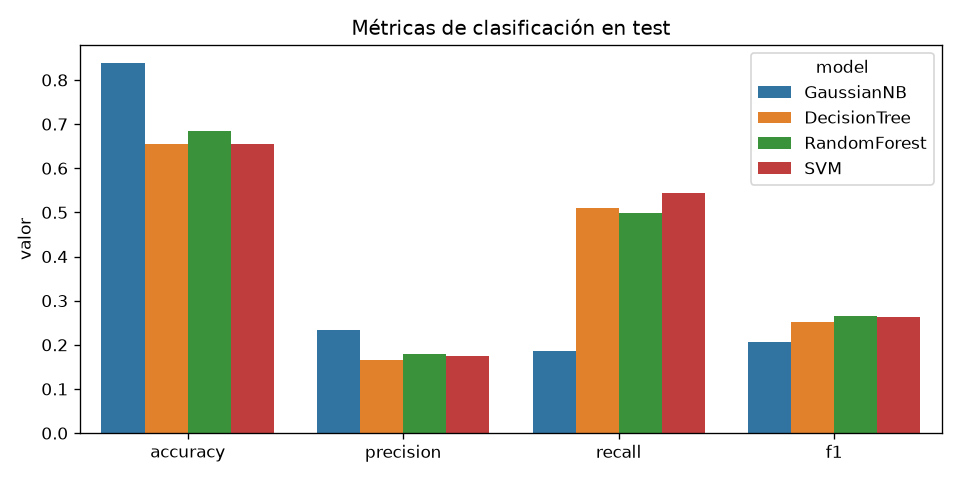

In [5]:
ev.plot_metrics_bars(metrics)
display(Image(filename="reports/figures/comparativa_metricas.png"))

El **accuracy** es alto para casi todos (por el desbalance) y no distingue modelos; **precision**, **recall** y **F1** sí muestran los compromisos.

### Barras de regresión

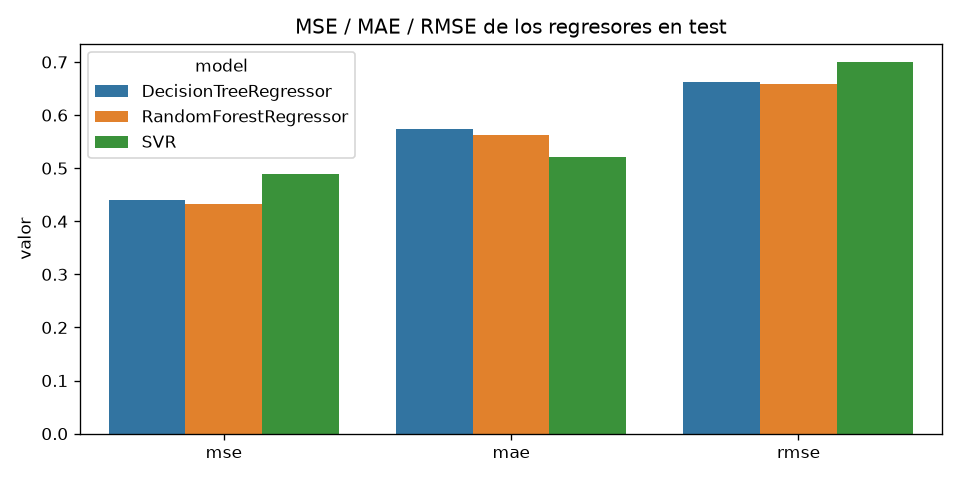

In [6]:
ev.plot_regression_bars(reg_metrics)
display(Image(filename="reports/figures/comparativa_regresion.png"))

### Matrices de confusión

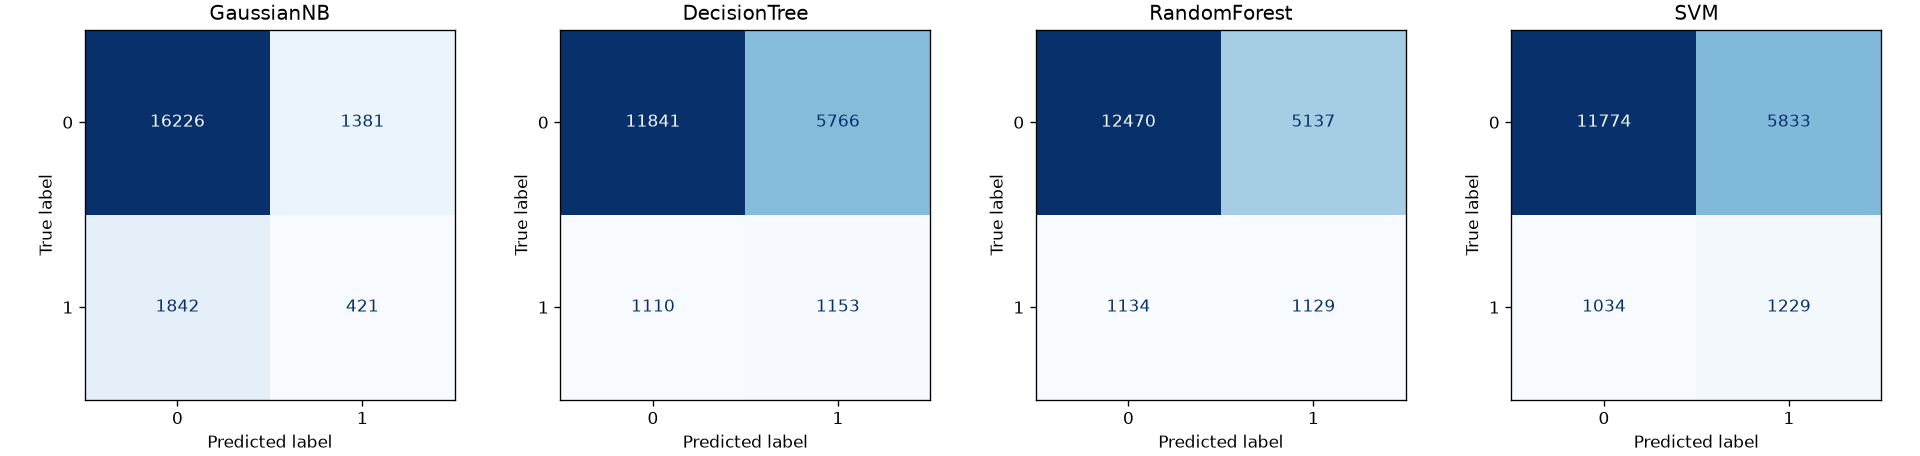

In [7]:
ev.plot_confusion_matrices(models, X_test, y_test)
display(Image(filename="reports/figures/matrices_confusion.png"))

Cada modelo hace un compromiso distinto: unos marcan a muchos pacientes (recall alto, muchas falsas alarmas) y otros son más cautelosos (precision mayor, detectan pocos reingresos). **F1 equilibra ambas.**

### Curvas precision-recall superpuestas

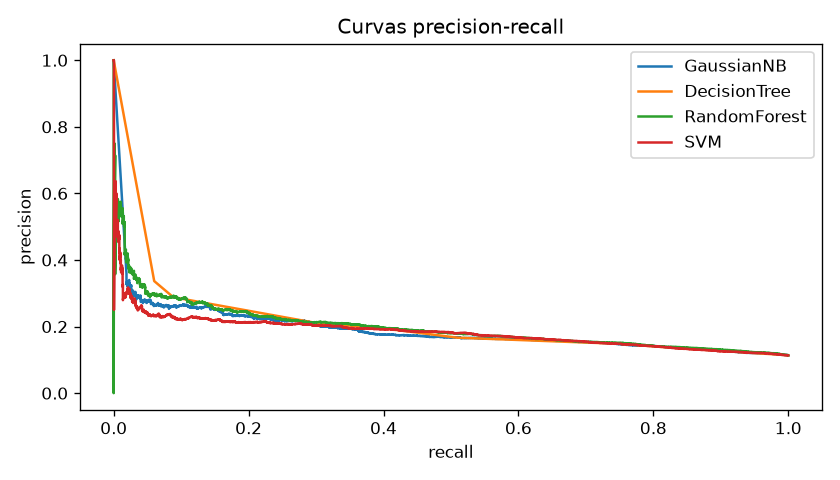

In [8]:
all_scores = {n: ev.risk_score(m, X_test) for n, m in models.items()}
ev.plot_comparison(all_scores, y_test)
display(Image(filename="reports/figures/comparativa_pr.png"))

## 4. Selección del modelo ganador (HU-13)

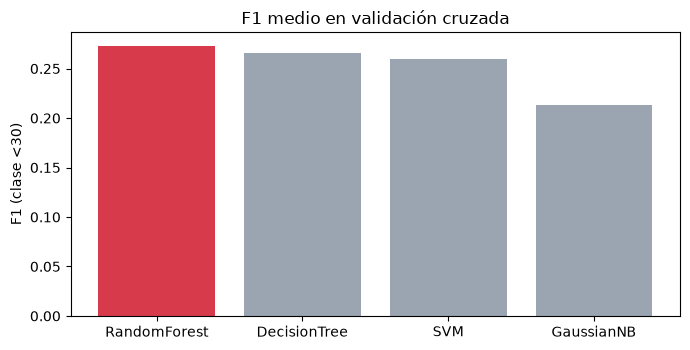

🏆 Clasificador ganador: RandomForest
🏆 Regresor ganador (menor RMSE): RandomForestRegressor


,F1 medio CV,recall (test)
model,,
RandomForest,0.273,0.4989
DecisionTree,0.266,0.5095
SVM,0.260,0.5431
GaussianNB,0.213,0.1860


In [9]:
cv_results = pd.read_csv(ART / "cv_results.csv")
rank = cv_results.groupby("model")["f1"].mean().round(3).rename("F1 medio CV").to_frame()
rank["recall (test)"] = metrics.set_index("model")["recall"]
rank = rank.sort_values(["F1 medio CV", "recall (test)"], ascending=False)
winner = rank.index[0]
winner_reg = reg_metrics.sort_values("rmse").iloc[0]["model"]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(
    rank.index,
    rank["F1 medio CV"],
    color=["#d73a4a" if m == winner else "#9aa5b1" for m in rank.index],
)
ax.set(title="F1 medio en validación cruzada", ylabel="F1 (clase <30)")
plt.tight_layout()
plt.show()
print(f"🏆 Clasificador ganador: {winner}")
print(f"🏆 Regresor ganador (menor RMSE): {winner_reg}")
rank